# Healthcare News Scraping

Devon Farber | Boston University MET CS688 coursework

Collects healthcare news with Requests and Beautiful Soup, removes duplicate titles, checks missing fields, exports CSV, and plots keyword frequencies.

## Results and reproducibility
Recorded output: 50 unique articles. Live search results and page selectors may change.

Saved outputs are retained from the submitted notebook. This portfolio packaging did not rerun the analysis.

See the repository README for setup and input requirements.


In [1]:
!pip install requests beautifulsoup4 pandas matplotlib

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
keywords = [
    "Artificial Intelligence",
    "Cancer",
    "Clinical Trials"
]

search_query = '"artificial intelligence" cancer "clinical trials"'

print("Our three keywords are:")
for keyword in keywords:
    print("-", keyword)

print("\nSearch query:")
print(search_query)

Our three keywords are:
- Artificial Intelligence
- Cancer
- Clinical Trials

Search query:
"artificial intelligence" cancer "clinical trials"


In [4]:
from urllib.parse import quote_plus

encoded_query = quote_plus(search_query)

url = f"https://www.bing.com/news/search?q={encoded_query}"

print("Bing News URL:")
print(url)

Bing News URL:
https://www.bing.com/news/search?q=%22artificial+intelligence%22+cancer+%22clinical+trials%22


In [5]:
headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/126.0 Safari/537.36"
    ),
    "Accept-Language": "en-US,en;q=0.9"
}

response = requests.get(
    url,
    headers=headers,
    timeout=15
)

print("Status code:", response.status_code)
print("HTML characters received:", len(response.text))

Status code: 200
HTML characters received: 122014


In [6]:
soup = BeautifulSoup(response.text, "html.parser")

print("Page title:")
print(soup.title)

Page title:
<title>"artificial intelligence" cancer "clinical trials" - Search News</title>


In [7]:
title_elements = soup.select("a.title")

print("Number of article titles found:", len(title_elements))

print("\nFirst few article titles:\n")

for title in title_elements[:10]:
    print("-", title.get_text(" ", strip=True))

Number of article titles found: 8

First few article titles:

- AI Could Cut 10 Weeks From Cancer Trials. Drugmakers Could Save Millions.
- Thoracic Oncology Innovations: Dr. Daniel Przybysz on AI, Global Trials, and Targeted Radiotherapy
- Enhancing Outcome Measurement in Oncology Clinical Trials Through Artificial Intelligence: A Scoping Review
- FDA pilots AI and real-time data reviews to speed some clinical trials
- Artificial Intelligence Tool for Optimizing Eligibility Screening for Clinical Trials in a Large Community Cancer Center
- Artificial intelligence improves risk stratification in oropharyngeal cancer
- A Quantum Mechanics Approach to Artificial Intelligence Can Improve Cancer Outcomes
- New artificial intelligence tool may help personalize ovarian cancer treatment from day one


In [8]:
snippet_elements = soup.select(".snippet")

print("Number of snippets found:", len(snippet_elements))

print("\nFirst few snippets:\n")

for snippet in snippet_elements[:8]:
    print("-", snippet.get_text(" ", strip=True))
    print()

Number of snippets found: 8

First few snippets:

- AI agents could accelerate the clinical development of cancer medicine by approximately 10 weeks while reducing direct operating costs by as much as $5.6 million in late-stage trials.

- Radiation oncologist Dr. Daniel Przybysz discusses AI integration, global clinical trial equity, and targeted lung cancer ...

- Artificial intelligence (AI) offers opportunities to enhance the efficiency, precision, and patient-centeredness of oncology trials. Deep learning systems integrate and analyze large data sets to ...

- A cancer patient enrolled in a clinical trial today might wait months before regulators ever see the safety data generated by their treatment. The FDA wants to change that, and it has started running ...

- Less than 5% of patients with cancer enroll in clinical trials, and 1 in 5 trials are stopped for poor accrual. We evaluated an automated clinical trial matching system that uses natural language ...

- A team led by inves

In [9]:
titles = [
    title.get_text(" ", strip=True)
    for title in title_elements
]

abstracts = [
    snippet.get_text(" ", strip=True)
    for snippet in snippet_elements
]

urls = [
    title.get("href", "")
    for title in title_elements
]

print("Titles:", len(titles))
print("Abstracts:", len(abstracts))
print("URLs:", len(urls))

page_df = pd.DataFrame({
    "title": titles,
    "abstract": abstracts,
    "url": urls
})

page_df

Titles: 8
Abstracts: 8
URLs: 8


,title,abstract,url
0,AI Could Cut 10 Weeks From Cancer Trials. Drug...,AI agents could accelerate the clinical develo...,https://www.ibtimes.com/ai-could-cut-10-weeks-...
1,Thoracic Oncology Innovations: Dr. Daniel Przy...,Radiation oncologist Dr. Daniel Przybysz discu...,https://www.latimes.com/doctors-scientists/med...
2,Enhancing Outcome Measurement in Oncology Clin...,Artificial intelligence (AI) offers opportunit...,https://ascopubs.org/doi/10.1200/CCI-26-00014
3,FDA pilots AI and real-time data reviews to sp...,A cancer patient enrolled in a clinical trial ...,https://www.msn.com/en-us/technology/artificia...
4,Artificial Intelligence Tool for Optimizing El...,Less than 5% of patients with cancer enroll in...,https://ascopubs.org/doi/abs/10.1200/CCI.19.00...
5,Artificial intelligence improves risk stratifi...,A team led by investigators at Mass General Br...,https://www.news-medical.net/news/20251223/Art...
6,A Quantum Mechanics Approach to Artificial Int...,Traditional AI models usually require enormous...,https://healthcare.utah.edu/huntsmancancerinst...
7,New artificial intelligence tool may help pers...,Researchers from the University of Minnesota M...,https://medicalxpress.com/news/2026-02-artific...


In [10]:
page2_url = f"https://www.bing.com/news/search?q={encoded_query}&first=11"

page2_response = requests.get(
    page2_url,
    headers=headers,
    timeout=15
)

page2_soup = BeautifulSoup(page2_response.text, "html.parser")

page2_titles = page2_soup.select("a.title")
page2_snippets = page2_soup.select(".snippet")

print("Page 2 status code:", page2_response.status_code)
print("Page 2 titles found:", len(page2_titles))
print("Page 2 snippets found:", len(page2_snippets))

print("\nFirst few titles from page 2:\n")

for title in page2_titles[:5]:
    print("-", title.get_text(" ", strip=True))

Page 2 status code: 200
Page 2 titles found: 7
Page 2 snippets found: 7

First few titles from page 2:

- Clinical Trial Patient Matching: A Real-Time, Common Data Model and Artificial Intelligence–Driven System for Semiautomated Patient Prescreening in Cancer Clinical Trials
- AI biotech Insitro’s Daphne Koller on how to speed up clinical trials
- Artificial intelligence (AI)–assisted eligibility screening for prostate cancer clinical trial matching.
- A Quantum Mechanics Approach to Artificial Intelligence Can Improve Cancer Outcomes
- Enhancing Outcome Measurement in Oncology Clinical Trials Through Artificial Intelligence: A Scoping Review


In [11]:
page1_title_texts = {
    title.get_text(" ", strip=True)
    for title in title_elements
}

page2_title_texts = {
    title.get_text(" ", strip=True)
    for title in page2_titles
}

duplicates = page1_title_texts.intersection(page2_title_texts)

print("Duplicate titles between page 1 and page 2:", len(duplicates))

print("\nDuplicates found:\n")

for title in duplicates:
    print("-", title)

Duplicate titles between page 1 and page 2: 2

Duplicates found:

- Enhancing Outcome Measurement in Oncology Clinical Trials Through Artificial Intelligence: A Scoping Review
- A Quantum Mechanics Approach to Artificial Intelligence Can Improve Cancer Outcomes


In [12]:
import time

all_articles = []
seen_titles = set()

page_number = 1
first_result = 1

while len(all_articles) < 50 and page_number <= 20:

    page_url = (
        f"https://www.bing.com/news/search?"
        f"q={encoded_query}&first={first_result}"
    )

    response_page = requests.get(
        page_url,
        headers=headers,
        timeout=15
    )

    soup_page = BeautifulSoup(
        response_page.text,
        "html.parser"
    )

    titles_page = soup_page.select("a.title")
    snippets_page = soup_page.select(".snippet")

    print(
        f"Page {page_number}: "
        f"{len(titles_page)} titles found"
    )

    for title_element, snippet_element in zip(
        titles_page,
        snippets_page
    ):

        title = title_element.get_text(
            " ",
            strip=True
        )

        abstract = snippet_element.get_text(
            " ",
            strip=True
        )

        article_url = title_element.get(
            "href",
            ""
        )

        if title not in seen_titles:

            seen_titles.add(title)

            all_articles.append({
                "title": title,
                "abstract": abstract,
                "url": article_url
            })

        if len(all_articles) >= 50:
            break

    print(
        "Unique articles collected:",
        len(all_articles)
    )

    first_result += 10
    page_number += 1

    time.sleep(1)

print("\nFinished!")
print("Total unique articles:", len(all_articles))

Page 1: 9 titles found
Unique articles collected: 9
Page 2: 7 titles found
Unique articles collected: 13
Page 3: 5 titles found
Unique articles collected: 15
Page 4: 6 titles found
Unique articles collected: 21
Page 5: 6 titles found
Unique articles collected: 25
Page 6: 5 titles found
Unique articles collected: 27
Page 7: 6 titles found
Unique articles collected: 33
Page 8: 9 titles found
Unique articles collected: 42
Page 9: 4 titles found
Unique articles collected: 45
Page 10: 6 titles found
Unique articles collected: 50

Finished!
Total unique articles: 50


In [13]:
final_df = pd.DataFrame(all_articles)

print("Total rows:", len(final_df))
print("Duplicate titles:", final_df["title"].duplicated().sum())
print("Missing titles:", final_df["title"].isna().sum())
print("Missing abstracts:", final_df["abstract"].isna().sum())

final_df.head(10)

Total rows: 50
Duplicate titles: 0
Missing titles: 0
Missing abstracts: 0


,title,abstract,url
0,Thoracic Oncology Innovations: Dr. Daniel Przy...,Radiation oncologist Dr. Daniel Przybysz discu...,https://www.latimes.com/doctors-scientists/med...
1,Harnessing Artificial Intelligence for the Man...,"Despite this, only a small fraction of patient...",https://ascopubs.org/doi/10.1200/EDBK-26-515754
2,FDA pilots AI and real-time data reviews to sp...,A cancer patient enrolled in a clinical trial ...,https://www.msn.com/en-us/technology/artificia...
3,Artificial Intelligence Tool for Optimizing El...,Less than 5% of patients with cancer enroll in...,https://ascopubs.org/doi/abs/10.1200/CCI.19.00...
4,AI Could Cut 10 Weeks From Cancer Trials. Drug...,AI agents could accelerate the clinical develo...,https://www.ibtimes.com/ai-could-cut-10-weeks-...
5,Artificial intelligence improves risk stratifi...,A team led by investigators at Mass General Br...,https://www.news-medical.net/news/20251223/Art...
6,A Quantum Mechanics Approach to Artificial Int...,Traditional AI models usually require enormous...,https://healthcare.utah.edu/huntsmancancerinst...
7,New artificial intelligence tool may help pers...,Researchers from the University of Minnesota M...,https://medicalxpress.com/news/2026-02-artific...
8,Artificial intelligence improves diagnostic ac...,Artificial intelligence (AI) is increasingly r...,https://www.news-medical.net/news/20260626/Art...
9,Enhancing Outcome Measurement in Oncology Clin...,Artificial intelligence (AI) offers opportunit...,https://ascopubs.org/doi/pdf/10.1200/CCI-26-00014


In [14]:
blank_titles = (final_df["title"].str.strip() == "").sum()
blank_abstracts = (final_df["abstract"].str.strip() == "").sum()
blank_urls = (final_df["url"].str.strip() == "").sum()

print("Blank titles:", blank_titles)
print("Blank abstracts:", blank_abstracts)
print("Blank URLs:", blank_urls)

Blank titles: 0
Blank abstracts: 0
Blank URLs: 0


In [15]:
csv_filename = "CS688_healthcare_news_articles.csv"

final_df.to_csv(csv_filename, index=False)

print("CSV saved successfully!")
print("File name:", csv_filename)
print("Rows saved:", len(final_df))

CSV saved successfully!
File name: CS688_healthcare_news_articles.csv
Rows saved: 50


In [16]:
from google.colab import files

files.download(csv_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
keyword_counts = {}

for keyword in keywords:
    count = final_df["title"].str.lower().str.count(keyword.lower()).sum()
    keyword_counts[keyword] = count

print("Keyword frequencies in article titles:\n")

for keyword, count in keyword_counts.items():
    print(f"{keyword}: {count}")

Keyword frequencies in article titles:

Artificial Intelligence: 34
Cancer: 27
Clinical Trials: 9


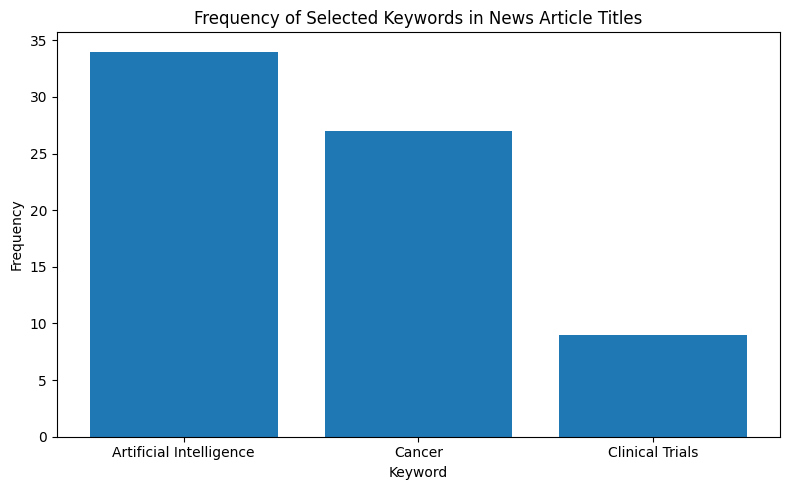

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(
    keyword_counts.keys(),
    keyword_counts.values()
)

plt.title("Frequency of Selected Keywords in News Article Titles")
plt.xlabel("Keyword")
plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

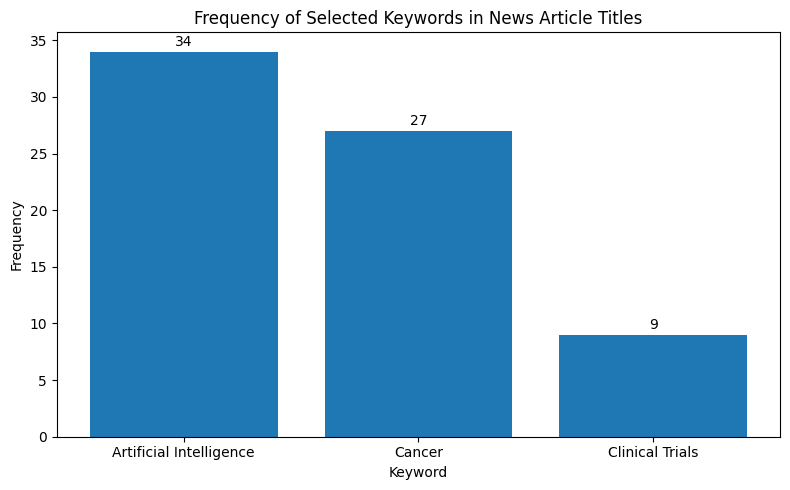

In [19]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    keyword_counts.keys(),
    keyword_counts.values()
)

plt.title("Frequency of Selected Keywords in News Article Titles")
plt.xlabel("Keyword")
plt.ylabel("Frequency")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "CS688_keyword_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
from google.colab import files

files.download("CS688_keyword_frequency.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>